<a href="https://colab.research.google.com/github/satyakatari820-tech/Bridge-load-distribution-calculator-/blob/main/Bridge_load_distribution_calculator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Simple user inputs
L = float(input("Enter bridge length (m): "))
x = float(input("Enter load position from left support (m): "))
W = float(input("Enter load value (kN): "))

# Check the load position
if x < 0 or x > L:
    raise ValueError("Load position must be between 0 and the bridge length.")

print("\nInputs:")
print("Bridge length =", L, "m")
print("Load position =", x, "m")
print("Load =", W, "kN")

Enter bridge length (m): 70
Enter load position from left support (m): 50
Enter load value (kN): 20

Inputs:
Bridge length = 70.0 m
Load position = 50.0 m
Load = 20.0 kN


In [ ]:
# Matrix equation AX = B

A = np.array([
    [1, 1],
    [0, L]
], dtype=float)

B = np.array([
    W,
    W * x
], dtype=float)

print("\nMatrix A:")
print(A)

print("\nMatrix B:")
print(B)


Matrix A:
[[ 1.  1.]
 [ 0. 70.]]

Matrix B:
[  20. 1000.]


In [ ]:
# Check whether the system has a unique solution
det_A = np.linalg.det(A)

print("\nDeterminant of A =", det_A)

if abs(det_A) < 1e-10:
    raise ValueError("No unique solution because det(A) = 0.")

# Matrix inverse method
A_inv = np.linalg.inv(A)

X = A_inv @ B

RA = X[0]
RB = X[1]

print("\nA inverse:")
print(A_inv)

print("\nAX = B solution:")
print(X)

print(f"\nLeft support reaction  RA = {RA:.2f} kN")
print(f"Right support reaction RB = {RB:.2f} kN")


Determinant of A = 70.00000000000003

A inverse:
[[ 1.         -0.01428571]
 [ 0.          0.01428571]]

AX = B solution:
[ 5.71428571 14.28571429]

Left support reaction  RA = 5.71 kN
Right support reaction RB = 14.29 kN


In [ ]:
print("\n--- Mathematical Calculation ---")

print(f"Equation 1: RA + RB = {W:.2f}")

print(f"Equation 2: {L:.2f} RB = {W:.2f} × {x:.2f}")

print(f"\nRB = ({W:.2f} × {x:.2f}) / {L:.2f}")
print(f"RB = {RB:.2f} kN")

print(f"\nRA = {W:.2f} - {RB:.2f}")
print(f"RA = {RA:.2f} kN")

print("\nCheck:")
print(f"RA + RB = {RA + RB:.2f} kN")
print(f"Applied load = {W:.2f} kN")


--- Mathematical Calculation ---
Equation 1: RA + RB = 20.00
Equation 2: 70.00 RB = 20.00 × 50.00

RB = (20.00 × 50.00) / 70.00
RB = 14.29 kN

RA = 20.00 - 14.29
RA = 5.71 kN

Check:
RA + RB = 20.00 kN
Applied load = 20.00 kN


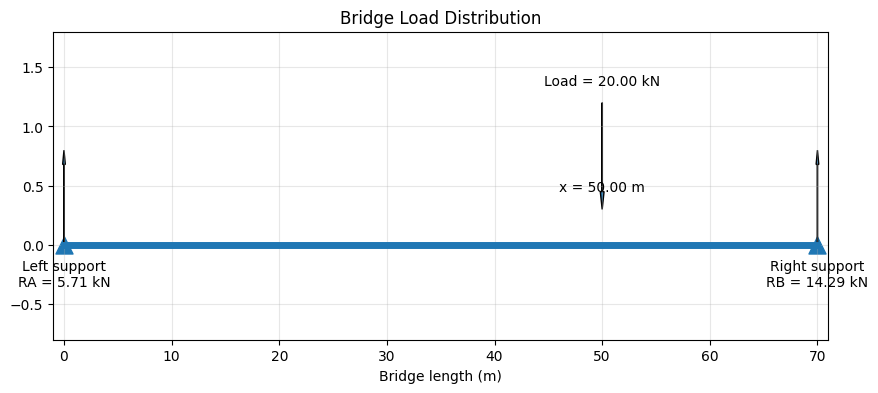

In [ ]:
# Visualize bridge, supports and load

fig, ax = plt.subplots(figsize=(10, 4))

# Bridge
ax.plot([0, L], [0, 0], linewidth=5)

# Supports
ax.scatter([0, L], [0, 0], s=150, marker="^")

# Load
ax.arrow(
    x, 1.2,
    0, -0.9,
    width=0.03,
    head_width=0.35,
    head_length=0.15,
    length_includes_head=True
)

# Reaction arrows
ax.arrow(
    0, 0,
    0, 0.8,
    width=0.02,
    head_width=0.25,
    head_length=0.12,
    length_includes_head=True
)

ax.arrow(
    L, 0,
    0, 0.8,
    width=0.02,
    head_width=0.25,
    head_length=0.12,
    length_includes_head=True
)

# Labels
ax.text(0, -0.35, f"Left support\nRA = {RA:.2f} kN", ha="center")
ax.text(L, -0.35, f"Right support\nRB = {RB:.2f} kN", ha="center")

ax.text(x, 1.35, f"Load = {W:.2f} kN", ha="center")
ax.text(x, 0.45, f"x = {x:.2f} m", ha="center")

ax.set_xlim(-1, L + 1)
ax.set_ylim(-0.8, 1.8)
ax.set_xlabel("Bridge length (m)")
ax.set_title("Bridge Load Distribution")
ax.grid(True, alpha=0.3)

plt.show()